# 03 — Pandas: EDA práctica y visualización con Matplotlib


Objetivos:

- Profundizar en **EDA** con pandas: valores nulos, duplicados, outliers.
- Joins y merges entre DataFrames.
- Visualización con **matplotlib** (histogramas, boxplots, barras, dispersión).


## 1. Cargar dataset sintético y provocar nulos/duplicados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
n = 300
df = pd.DataFrame({
    "id": range(1, n+1),
    "edad": rng.integers(18, 75, size=n),
    "ingresos": rng.normal(26000, 9000, size=n).round(2),
    "ciudad": rng.choice(["Cádiz","Sevilla","Málaga","Córdoba"], size=n),
    "satisfaccion": rng.integers(1, 6, size=n),
})
# Introducir nulos y duplicados
df.loc[rng.choice(df.index, 10, replace=False), "ingresos"] = np.nan
df = pd.concat([df, df.sample(5, random_state=1)], ignore_index=True)  # duplicados
df.head()

,id,edad,ingresos,ciudad,satisfaccion
0,1,71,26119.92,Cádiz,2
1,2,53,19750.37,Málaga,2
2,3,56,23059.83,Sevilla,5
3,4,69,20957.92,Sevilla,3
4,5,50,26071.63,Cádiz,3


## 2. Nulos y duplicados

In [2]:
df.isna().sum(), df.duplicated().sum()

(id               0
 edad             0
 ingresos        11
 ciudad           0
 satisfaccion     0
 dtype: int64,
 np.int64(5))

In [4]:
# Imputación simple
df["ingresos"] = df["ingresos"].fillna(df["ingresos"].median())
df = df.drop_duplicates().reset_index(drop=True)
df.isna().sum(), df.duplicated().sum()

(id              0
 edad            0
 ingresos        0
 ciudad          0
 satisfaccion    0
 dtype: int64,
 np.int64(0))

## 3. Detección simple de outliers

In [6]:
q1 = df["ingresos"].quantile(0.25)
q3 = df["ingresos"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5*iqr
upper = q3 + 1.5*iqr
outliers = df[(df["ingresos"] < lower) | (df["ingresos"] > upper)]
len(outliers), lower, upper

(3, np.float64(3785.9262499999986), np.float64(46700.69625))

## 4. Joins / merges

In [7]:
ciudades_info = pd.DataFrame({
    "ciudad": ["Cádiz","Sevilla","Málaga","Córdoba"],
    "poblacion_k": [116, 684, 579, 326],
})
df_merged = df.merge(ciudades_info, on="ciudad", how="left")
df_merged.head()

,id,edad,ingresos,ciudad,satisfaccion,poblacion_k
0,1,71,26119.92,Cádiz,2,116
1,2,53,19750.37,Málaga,2,579
2,3,56,23059.83,Sevilla,5,684
3,4,69,20957.92,Sevilla,3,684
4,5,50,26071.63,Cádiz,3,116


## 5. Visualización con matplotlib

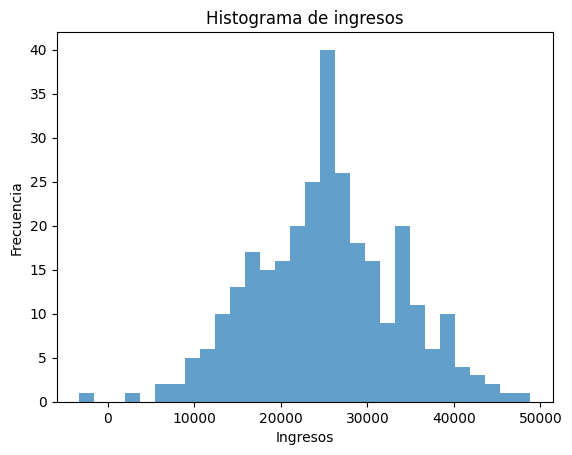

In [8]:
# Histograma de ingresos
plt.figure()
df["ingresos"].plot(kind="hist", bins=30, alpha=0.7)
plt.title("Histograma de ingresos")
plt.xlabel("Ingresos")
plt.ylabel("Frecuencia")
plt.show()

<Figure size 640x480 with 0 Axes>

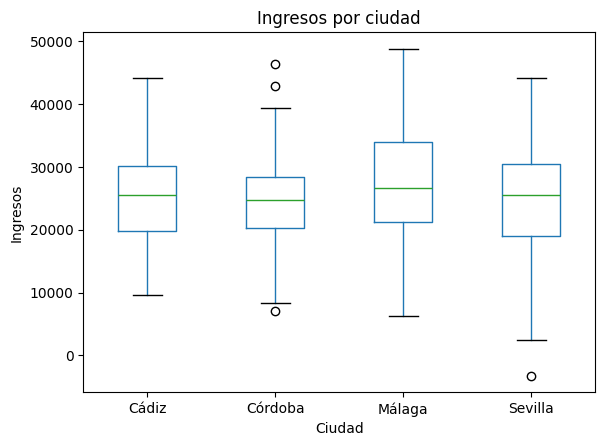

In [9]:
# Boxplot por ciudad
plt.figure()
df.boxplot(column="ingresos", by="ciudad", grid=False)
plt.title("Ingresos por ciudad")
plt.suptitle("")
plt.xlabel("Ciudad")
plt.ylabel("Ingresos")
plt.show()

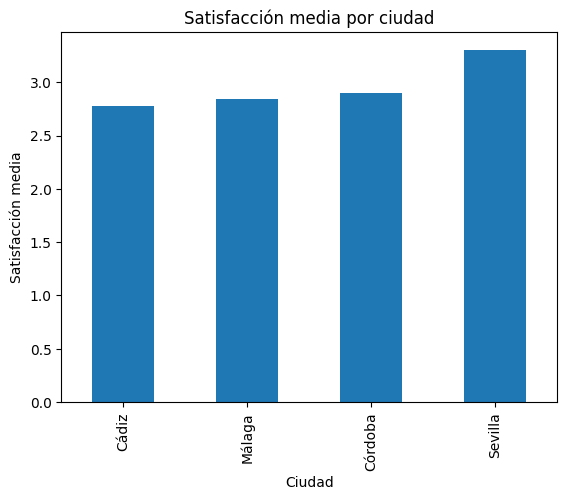

In [10]:
# Barras: media de satisfacción por ciudad
media_sat = df.groupby("ciudad")["satisfaccion"].mean().sort_values()
plt.figure()
media_sat.plot(kind="bar")
plt.title("Satisfacción media por ciudad")
plt.xlabel("Ciudad")
plt.ylabel("Satisfacción media")
plt.show()

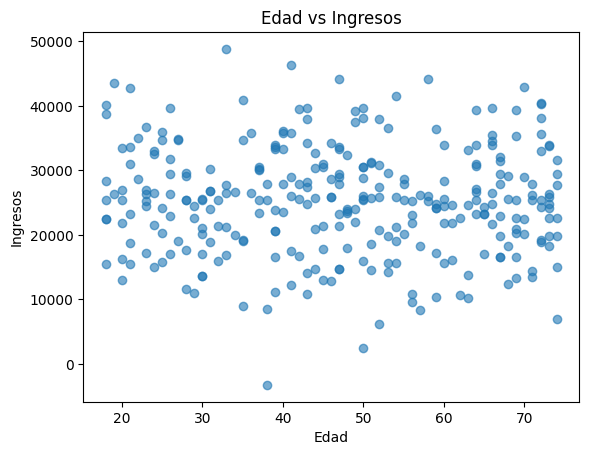

In [11]:
# Dispersión edad vs ingresos
plt.figure()
plt.scatter(df["edad"], df["ingresos"], alpha=0.6)
plt.title("Edad vs Ingresos")
plt.xlabel("Edad")
plt.ylabel("Ingresos")
plt.show()

## 📝 Ejercicios

1) Repite el histograma de `edad` con 20 bins.  
2) Identifica outliers en `satisfaccion` usando IQR. ¿Hay muchos?  
3) Une (`merge`) con un DataFrame con código postal ficticio y comprueba el resultado.
